# 05. 원인 근거 보강과 로컬 에이전트(질문하기)
**목적**
1. '판단 불가'가 많던 여러 날 연속 증가(지속 변화)에 쓸 **근거**를 데이터에서 찾는다
2. 판정 모델(tev1)에 근거를 **어떤 형태로** 넘겨야 하는지 실험한다
3. 외부 LLM 없이 질문에 답하는 **로컬 에이전트**를 만들고, 질문 분류 성능을 평가한다

모든 계산은 `app/` 모듈을 그대로 부른다. 판정 모델은 이 PC의 Ollama(`127.0.0.1:11500`)에서 돈다.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False
from app.store.cache import CacheStore
from app.agent.tools import Toolbox
st = CacheStore("data/cache"); tb = Toolbox(st, None)
print("유동인구 기간:", st.island_series("유동인구").dropna().index.min().date(), "~", st.island_series("유동인구").dropna().index.max().date())

유동인구 기간: 2024-04-01 ~ 2025-03-31


## 1. 근거 후보 ① 월별 입도객 — 성수기·비수기 표시
방문목적별 입도객(허브 580)을 월 합계로 만들고, 주변 12개월 평균보다 ±5% 이상이면 성수기/비수기로 표시한다(본 서비스 임의 기준).

In [2]:
from app.analytics.context import season_index, SEASON_PCT
v = st.visitors
tbl = pd.DataFrame({"입도객(만 명)": (v / 1e4).round(1), "주변 12개월 평균 대비(%)": [None if season_index(v, m) is None else round(season_index(v, m), 1) for m in v.index]})
tbl["표시"] = tbl["주변 12개월 평균 대비(%)"].map(lambda x: "" if x is None or pd.isna(x) or abs(x) < SEASON_PCT else ("성수기" if x > 0 else "비수기"))
tbl.index = tbl.index.strftime("%Y-%m"); tbl

,입도객(만 명),주변 12개월 평균 대비(%),표시
dtYearMonth,,,
2024-04,211.4,2.1,
2024-05,216.1,4.4,
2024-06,200.8,-1.8,
2024-07,205.1,1.7,
2024-08,217.6,9.5,성수기
2024-09,191.4,-1.2,
2024-10,206.6,8.4,성수기
2024-11,185.7,-1.7,
2024-12,179.9,-4.4,


**읽은 것**: 2024년 7월은 +1.7%로 성수기 기준에 못 미친다. 7월 말 급증은 **한 달 안에서** 일어난 변화라 월 합계로는 보이지 않는다.
허브 데이터 목록에서 일별 입도객을 찾아봤지만 없었다(2026-11-11 확인) → 다른 일 단위 근거가 필요하다.

## 2. 근거 후보 ② 제주 전체 합계 — 이 지역만의 변화인가, 섬 전체의 흐름인가
43개 읍면동을 더한 '제주 전체' 시계열에도 같은 탐지 방법을 적용한다.

,제주 전체,기대값,점수
2024-07-24,4543863.0,4019360.0,1.44
2024-07-25,4677786.0,3999496.0,1.87
2024-07-26,4943834.0,4277937.0,1.83
2024-07-27,5777455.0,4964562.0,2.24
2024-07-28,6130446.0,4910341.0,3.36
2024-07-29,5948839.0,4331002.0,4.46
2024-07-30,6167172.0,4231150.0,5.33
2024-07-31,6332737.0,4245031.0,5.75
2024-08-01,6235057.0,4291744.0,5.35
2024-08-02,6329030.0,4492388.0,5.06


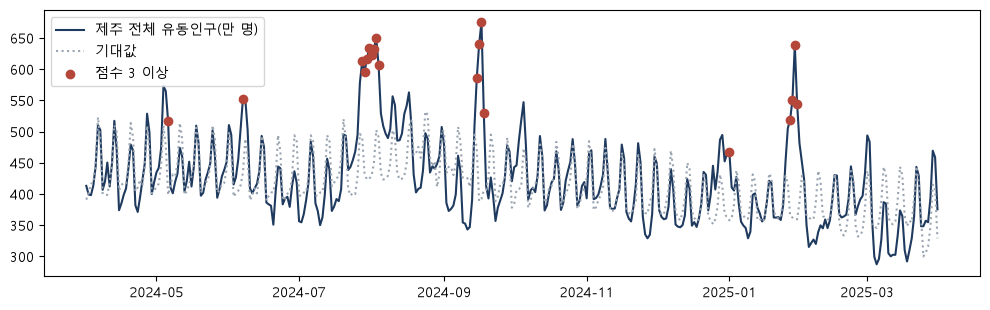

In [3]:
from app.analytics.detect import score_series
tot = st.island_series("유동인구"); _, ex, z = score_series(tot, "seasonal_z")
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(tot.index, tot / 1e4, color="#1F3A5F", label="제주 전체 유동인구(만 명)"); ax.plot(ex.index, ex / 1e4, ":", color="#9AA5B1", label="기대값")
hit = z[z >= 3].dropna(); ax.scatter(hit.index, tot.reindex(hit.index) / 1e4, color="#B5473A", zorder=3, label="점수 3 이상")
ax.legend(); plt.tight_layout()
pd.DataFrame({"제주 전체": tot, "기대값": ex.round(0), "점수": z.round(2)}).loc["2024-07-24":"2024-08-02"]

**읽은 것**: 7월 말에는 섬 전체 유동인구도 크게 늘었다 → 해변 지역의 증가는 '섬 전체 관광 수요 증가'와 함께 움직인 것으로 볼 수 있다.
→ `find_co_movements` 도구가 같은 읍면동의 다른 신호와 함께 **제주 전체 합계**도 확인하도록 바꿨다.

**보완(2026-11-11)**: 1년치로 다시 보니 삼도1동 2025-03-29 와이파이(점수 13.7)처럼 한 곳의 큰 급증이 제주 전체 합계까지 끌어올렸다. 그래서 제주 전체 합계는 **설명하려는 읍면동을 뺀 나머지 합계**로 비교한다(`tests/test_agent.py::test_island_total_excludes_the_region_itself`).

## 3. 판정 모델에 근거를 넘기는 형태 실험 (이호동 7월 말 사례)
같은 근거를 ① JSON 그대로 ② 한국어 문장 ③ 영어 문장으로 넘겨 비교한다.

In [4]:
import json, requests
from app.llm.judge import CAUSES, CAUSE_KO, evidence_text
ev = {"anomaly": {"emd": "제주시 이호동", "signal": "유동인구", "date": "2024-07-28", "pct": 103.8, "kind": "지속 변화", "days": 4},
      "context": [], "co_movements": [{"signal": "제주 전체 유동인구", "date": "2024-07-29", "z": 4.83, "direction": "up"}]}
en = ("Anomaly: domestic visitor population in Iho-dong (Jeju City) was above its normal same-weekday level for 4 consecutive days, "
      "peaking at +103.8% vs expected.\nEvidence 1 (co-movement): the island-wide total visitor population of Jeju also rose sharply (z=4.83, up); "
      "this is not local.\nEvidence 2 (context): no severe weather, no public holiday, no registered event.")
def ask(state):
    body = {"model": "tev1:4b", "state": state, "questions": {"cause": {"type": "choice",
            "instructions": "Which listed cause best explains this anomaly in Jeju tourism/transport data? Judge only from the given evidence.", "criteria": CAUSES}}}
    a = requests.post("http://127.0.0.1:11500/v1/systemone", json=body, timeout=120).json()["answers"]["cause"]
    return CAUSE_KO[a["choice"]], round(a["probabilities"][a["choice"]], 2), round(a["probabilities"].get("tourism_demand", 0), 2)
print(evidence_text(ev))
pd.DataFrame([("① JSON", *ask(json.dumps(ev, ensure_ascii=False))), ("② 한국어 문장(채택)", *ask(evidence_text(ev))), ("③ 영어 문장", *ask(en))],
             columns=["입력 형태", "판정", "판정 확률", "'관광 수요 변화' 확률"])

이상 신호: 제주시 이호동 유동인구 — 2024-07-28 기준 지속 변화(4일), 평소(같은 요일 기준선) 대비 +103.8%.
동반 변화: 제주 전체 유동인구도 2024-07-29에 평소보다 크게 움직였다(점수 4.83, 증가). 즉 이 지역만의 변화가 아니라 섬 전체에서 함께 움직였다.
맥락: 기상 특이사항 없음, 공휴일 없음, 지역이 확인된 행사 없음.


,입력 형태,판정,판정 확률,'관광 수요 변화' 확률
0,① JSON,판단 불가,0.62,0.29
1,② 한국어 문장(채택),관광 수요 변화,0.65,0.65
2,③ 영어 문장,관광 수요 변화,0.62,0.62


**읽은 것**: JSON을 그대로 넘기면 '제주 전체'라는 근거의 뜻을 놓치고 '판단 불가'로 답한다. 문장으로 풀어 주면 '관광 수요 변화'로 판정한다.
사전 실험(노트북 03)은 처음부터 문장형으로 했으므로, **실제 판정 경로도 문장형(`evidence_text`)으로 맞췄다**. 영어가 약간 더 높지만 근거 원문(기상·행사 이름)이 한국어라 한국어 문장을 채택했다.

## 4. 실제 이상 구간 상위 15개: 규칙 기반 vs tev1 판정

In [5]:
from app.analytics.detect import detect_anomalies, group_episodes
from app.llm.judge import judge_cause, rule_judge
eps = sorted(((abs(e.peak.score), emd, e) for emd in st.regions("유동인구")
              for e in group_episodes(detect_anomalies(st.series("유동인구", emd), threshold=3.5))), key=lambda x: -x[0])[:15]
rows = []
for _, emd, e in eps:
    day = str(e.peak.date.date())
    co = tb.dispatch("find_co_movements", {"date": day, "emd": emd, "window": 1, "exclude_signal": "유동인구"}, "R2").data["co_movements"]
    cx = tb.dispatch("check_context", {"date": day, "emd": emd}, "R3").data["items"]
    evd = {"anomaly": {"emd": emd, "signal": "유동인구", "date": day, "pct": round(e.peak.pct * 100, 1), "kind": e.kind, "days": e.days}, "context": cx, "co_movements": co}
    j = judge_cause(evd)
    rows.append({"읍면동": emd, "구간": f"{e.start.date()}~{e.end.date()}", "유형": e.kind, "기대 대비(%)": round(e.peak.pct * 100), "맥락": ", ".join(c["kind"] for c in cx),
                 "동반 변화": ", ".join(c["signal"] for c in co), "규칙": CAUSE_KO[rule_judge(evd).choice], "tev1:4b": CAUSE_KO[j.choice], "확률": round(j.probabilities.get(j.choice, 0), 2)})
cmp = pd.DataFrame(rows); print("규칙과 tev1 일치:", (cmp["규칙"] == cmp["tev1:4b"]).sum(), "/", len(cmp)); cmp

규칙과 tev1 일치: 15 / 15


,읍면동,구간,유형,기대 대비(%),맥락,동반 변화,규칙,tev1:4b,확률
0,제주시 삼도1동,2025-03-28~2025-03-30,지속 변화,170,visitors,"와이파이, 버스, 제주 전체 와이파이",관광 수요 변화,관광 수요 변화,0.63
1,서귀포시 효돈동,2025-01-27~2025-01-30,지속 변화,250,"holiday, holiday, holiday, visitors","제주 전체 유동인구, 제주 전체 버스",공휴일·연휴,공휴일·연휴,0.60
2,서귀포시 효돈동,2024-09-15~2024-09-18,지속 변화,243,"holiday, holiday, holiday",제주 전체 유동인구,공휴일·연휴,공휴일·연휴,0.78
3,제주시 일도2동,2025-01-25~2025-01-31,지속 변화,93,"holiday, holiday, holiday, visitors","와이파이, 버스, 제주 전체 유동인구, 제주 전체 버스",공휴일·연휴,공휴일·연휴,0.58
4,제주시 이호동,2024-07-26~2024-07-29,지속 변화,104,,제주 전체 유동인구,관광 수요 변화,관광 수요 변화,0.67
5,제주시 삼양동,2025-01-27~2025-01-31,지속 변화,104,"holiday, holiday, holiday, visitors","버스, 제주 전체 유동인구, 제주 전체 버스",공휴일·연휴,공휴일·연휴,0.51
6,제주시 화북동,2025-01-24~2025-01-31,지속 변화,76,"holiday, holiday, holiday, visitors","와이파이, 버스, 제주 전체 유동인구, 제주 전체 버스",공휴일·연휴,공휴일·연휴,0.50
7,제주시 삼양동,2024-09-15~2024-09-18,지속 변화,87,"holiday, holiday, holiday",제주 전체 유동인구,공휴일·연휴,공휴일·연휴,0.77
8,제주시 일도2동,2024-09-15~2024-09-18,지속 변화,72,"holiday, holiday, holiday",제주 전체 유동인구,공휴일·연휴,공휴일·연휴,0.75
9,서귀포시 서홍동,2025-01-28~2025-01-30,지속 변화,86,"holiday, holiday, holiday, visitors","제주 전체 유동인구, 제주 전체 버스",공휴일·연휴,공휴일·연휴,0.63


**읽은 것**
- 추석 연휴(2024-09-14~18) 구간은 공휴일 근거가 있어 '공휴일·연휴', 7월 말 해변 지역은 제주 전체 동반 증가 근거로 '관광 수요 변화'로 판정된다
- 근거가 없는 하루짜리 급변(일도1동 5/31)은 '판단 불가'(약 0.95) — 근거 없이 원인을 지어내지 않는다
- 이 표에서는 규칙과 tev1이 모두 같았다. 둘이 갈리는 사례와 정답 기준 평가는 가짜 이상 주입 평가(노트북 06 예정)에서 다룬다

## 5. 로컬 에이전트(질문하기 탭)
질문 분류는 tev1, 지역·날짜·신호는 규칙으로 추출, 계산은 정해진 도구 흐름, 답변 숫자는 검증기를 통과해야만 표시된다(외부 LLM 없음).

In [6]:
from app.agent.local import answer, INTENT_KO
from app.rag.corpus import load_corpus
from app.rag.index import build_index
tba = Toolbox(st, build_index(load_corpus(ROOT)))
for q in ["7월에 유동인구가 이상하게 많았던 곳 알려줘", "이호동 7월 28일에 사람이 왜 이렇게 많았어?", "반출 가능한 결과물 기준이 뭐야?", "오늘 점심 메뉴 추천해줘"]:
    r = answer(q, tba)
    print(f"Q. {q}\n   분류={INTENT_KO[r.intent]} ({r.router}) · 검증={'통과' if r.verified else '미통과'} · 도구 {[x.tool for x in r.results.values()]}")
    print("   " + r.final_text.replace("\n", "\n   ")[:700], "\n")

Q. 7월에 유동인구가 이상하게 많았던 곳 알려줘
   분류=이상 찾기 (tev1:4b) · 검증=통과 · 도구 ['scan_regions']
   유동인구 기준 2024-07-01~2024-07-31 동안 43개 읍면동 중 28곳에서 이상 구간 31개가 확인됐습니다(평소 변동폭 대비 점수가 큰 순) [R1].
   - 제주시 이호동 2024-07-26~2024-07-29(지속 변화): 가장 큰 날 2024-07-28 기대 대비 103.8% 많음, 점수 15.75 [R1].
   - 제주시 한림읍 2024-07-27~2024-07-31(지속 변화): 가장 큰 날 2024-07-31 기대 대비 89.9% 많음, 점수 7.27 [R1].
   - 제주시 애월읍 2024-07-28~2024-07-31(지속 변화): 가장 큰 날 2024-07-31 기대 대비 75.1% 많음, 점수 7.18 [R1].
   - 제주시 조천읍 2024-07-28~2024-07-31(지속 변화): 가장 큰 날 2024-07-31 기대 대비 91.6% 많음, 점수 6.54 [R1].
   - 제주시 구좌읍 2024-07-28~2024-07-31(지속 변화): 가장 큰 날 2024-07-30 기대 대비 101.4% 많음, 점수 6.47 [R1].
   이유가 궁금한 구간은 '읍면동 + 날짜 + 왜'로 물어보세요. 



Q. 이호동 7월 28일에 사람이 왜 이렇게 많았어?
   분류=원인 설명 (tev1:4b) · 검증=통과 · 도구 ['detect_anomalies', 'find_co_movements', 'check_context', 'judge_cause']
   제주시 이호동 유동인구에서 이상 구간 2개(이상일 7일)가 확인됐습니다 [R1].
   2024-07-26~2024-07-29(지속 변화): 가장 큰 날 2024-07-28 값은 96,373.0명으로 기대값 47,287.5보다 103.8% 많았습니다 [R1].
   같은 시기 제주 전체 유동인구도 2024-07-29에 평소보다 많았습니다(점수 4.37) [R2].
   2024-07-31~2024-08-02(지속 변화): 가장 큰 날 2024-08-02 값은 59,635.0명으로 기대값 40,282.5보다 48.0% 많았습니다 [R1].
   근거를 종합한 원인 후보는 '관광 수요 변화'(확률 66.5%, 확신도 중)입니다 [R4][R2][R3].
   이는 상관에 기반한 후보이며 인과를 뜻하지 않습니다. 



Q. 반출 가능한 결과물 기준이 뭐야?
   분류=문서 검색 (tev1:4b) · 검증=통과 · 도구 ['search_docs']
   관련 문서를 찾았습니다(원문 일부, 출처 포함) [R1].
   - 게시판 답변 — 3 반출·외부 LLM 전송 (대회 게시판 공식 답변 정리 §3 반출·외부 LLM 전송 (조각 1)): 질문 · 공식 답변 · 센터 원본/조회 결과를 외부 LLM에 / · 불가 (10/30) · 집계·가공 결과를 외부 LLM에 / · 데이터별 반출 기준 충족 범위에서 가능(10/30) / 텍스트 전송도 가능하나 기준 충족 검수·암호화 등 보안 조치 포함 권장 (11/3) / 항목별 일률 기준은… [R1]
   - 게시판 답변 — 5 권리 (대회 게시판 공식 답변 정리 §5 권리): 질문 · 공식 답변 · "결과물은 센터 소속"의 뜻 · 제출 파일의 비독점 이용 허락(5년 이상도 가능), 비수상작 포함, 아이디어·콘셉트는 대상 아님 / 센터 내에서만 탑재, 기획서·코드는 이용자에게 비공개 (11/3) · 대회 후 내 코드 계속 개발·활용 · 가능 / 단 「제주… [R1]
   - 제주빅데이터센터 데이터 반출 정책 (https://jejudatahub.net/community/notice/view/48 첨부 「제주빅데이터센터 데이터 반출 기준」(2026.09.01 개정) (조각 4)): 반출심사 ⑥ 심사결과 제주데이터허브 신청 이용기간 내 분석 완료 이용 데이터 별 확인 빅데이터센터 시스템 최대 5일 소요 이메일 통보 ① 제주데이터허브 홈페이지에서 이용신청 



Q. 오늘 점심 메뉴 추천해줘
   분류=범위 밖 (tev1:4b) · 검증=통과 · 도구 []
   이 질문은 다루지 않습니다. 이 도우미는 제주 관광·교통 데이터의 이상 신호 찾기, 변화 이유 후보 설명, 데이터 문서 검색만 답합니다. 예: '유동인구가 이상했던 곳 알려줘', '이호동 유동인구가 왜 늘었어?', '버스 데이터 출처가 뭐야?' 



## 6. 질문 분류 평가 (`python -m eval.intent_probe`)
- 설계용 24문항: 결합 방식을 정할 때 본 질문
- **평가 전용 12문항**: 결합 방식을 정하기 *전에* 따로 적어 커밋해 둔 질문(설계에 쓰지 않음)

In [7]:
res = {m: json.load(open(f"eval/results/intent_probe_{m.replace(':', '_')}.json", encoding="utf-8")) for m in ["tev1:4b", "tev1:0.8b"]}
pd.DataFrame([{"모델": m, "세트": k, "문항": r["summary"][k]["n"], "키워드 규칙": r["summary"][k]["rule_accuracy"],
               "모델 단독": r["summary"][k]["model_accuracy"], "모델+규칙 보완": r["summary"][k]["hybrid_accuracy"], "응답(초, 중앙값)": r["summary"][k]["sec_median"]}
              for m, r in res.items() for k in ["design", "heldout"]])

,모델,세트,문항,키워드 규칙,모델 단독,모델+규칙 보완,"응답(초, 중앙값)"
0,tev1:4b,design,24,0.917,0.875,0.958,0.049
1,tev1:4b,heldout,12,0.333,0.833,0.833,0.049
2,tev1:0.8b,design,24,0.917,0.917,0.958,0.028
3,tev1:0.8b,heldout,12,0.333,0.583,0.583,0.025


**읽은 것**
- 키워드 규칙은 설계용 질문에서 92%였지만 **처음 보는 질문에서 33%** — 내가 쓴 질문에 맞춰진 규칙은 일반화되지 않는다
- **tev1:4b는 처음 보는 질문에서도 83%** (0.8b는 58%) → 질문 분류는 4B 모델에 맡기고, 연결이 안 될 때만 규칙을 쓴다
- 모델+규칙 보완은 평가 전용 세트에서 모델 단독과 같았다(이득·손해 없음)
- 한계: 문항 수가 적고(36개) 질문을 내가 썼다 → 실제 사용자 질문으로 재평가 필요